# 23CSE301 - Lab Session 10
## ASVspoof 2017 CQCC classification

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.decomposition import PCA
from sklearn.ensemble import (
    AdaBoostClassifier,
    RandomForestClassifier,
    StackingClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20
OUTPUT_DIR = Path('Lab10_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)



In [2]:
dataset_candidates = [
    Path('ASVspoof2017_V2_CQCC.csv')
]
DATASET_PATH = next((path for path in dataset_candidates if path.is_file()), None)

if DATASET_PATH is None:
    raise FileNotFoundError(
        'Dataset not found. Place ASVspoof2017_V2_CQCC.csv beside this notebook '
        'or update DATASET_PATH to the correct CSV location.'
    )

data = pd.read_csv(DATASET_PATH)
if 'Label' not in data.columns:
    raise ValueError("The dataset must contain a 'Label' column.")

label_mapping = {'genuine': 0, 'spoof': 1}
label_text = data['Label'].astype(str).str.strip().str.lower()
unknown_labels = sorted(set(label_text.unique()) - set(label_mapping))
if unknown_labels:
    raise ValueError(f'Unexpected labels found: {unknown_labels}')

y = label_text.map(label_mapping).astype(int)
X = data.drop(columns=[column for column in ['FileName', 'Label'] if column in data.columns]).copy()
X = X.apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)

if X.shape[1] == 0:
    raise ValueError('No numeric CQCC feature columns were found.')

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print('Dataset:', DATASET_PATH.resolve())
print('Full dataset shape:', data.shape)
print('Feature matrix shape:', X.shape)
print('Training feature shape:', X_train.shape)
print('Testing feature shape:', X_test.shape)
print('\nClass distribution (0 = genuine, 1 = spoof):')
display(y.value_counts().sort_index().rename(index={0: 'genuine (0)', 1: 'spoof (1)'}).to_frame('Count'))
print('Missing feature values:', int(X.isna().sum().sum()))
print('Duplicate rows:', int(data.duplicated().sum()))

feature_names = X.columns.tolist()

Dataset: C:\Users\tanki\Downloads\Lab10_ASVspoof_Notebook\ASVspoof2017_V2_CQCC.csv
Full dataset shape: (3014, 182)
Feature matrix shape: (3014, 180)
Training feature shape: (2411, 180)
Testing feature shape: (603, 180)

Class distribution (0 = genuine, 1 = spoof):


,Count
Label,
genuine (0),1507
spoof (1),1507


Missing feature values: 0
Duplicate rows: 0


In [3]:
class CatBoostWrapper(ClassifierMixin, BaseEstimator):
    def __init__(self, iterations=200, depth=6, learning_rate=0.05, random_seed=42):
        self.iterations = iterations
        self.depth = depth
        self.learning_rate = learning_rate
        self.random_seed = random_seed

    def fit(self, X, y):
        from catboost import CatBoostClassifier
        self.model_ = CatBoostClassifier(
            iterations=self.iterations,
            depth=self.depth,
            learning_rate=self.learning_rate,
            loss_function='Logloss',
            verbose=False,
            allow_writing_files=False,
            random_seed=self.random_seed,
            thread_count=1,
        )
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        return np.asarray(self.model_.predict(X)).reshape(-1).astype(int)

    def predict_proba(self, X):
        return self.model_.predict_proba(X)


class XGBoostWrapper(ClassifierMixin, BaseEstimator):
    def __init__(self, n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.random_state = random_state

    def fit(self, X, y):
        from xgboost import XGBClassifier
        self.model_ = XGBClassifier(
            n_estimators=self.n_estimators,
            max_depth=self.max_depth,
            learning_rate=self.learning_rate,
            subsample=0.9,
            colsample_bytree=0.9,
            objective='binary:logistic',
            eval_metric='logloss',
            random_state=self.random_state,
            n_jobs=1,
        )
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        return self.model_.predict(X)

    def predict_proba(self, X):
        return self.model_.predict_proba(X)


def build_classifier_instances(random_state=RANDOM_STATE):
    """Return fresh instances of the Lab 09 classifiers and package availability notes."""
    classifiers = {
        'Support Vector Machine': SVC(
            C=2.0, kernel='rbf', probability=True, class_weight='balanced',
            random_state=random_state,
        ),
        'Decision Tree': DecisionTreeClassifier(
            class_weight='balanced', random_state=random_state,
        ),
        'Random Forest': RandomForestClassifier(
            n_estimators=120, class_weight='balanced', random_state=random_state,
            n_jobs=1,
        ),
        'AdaBoost': AdaBoostClassifier(
            n_estimators=100, learning_rate=0.5, random_state=random_state,
        ),
        'Naive Bayes': GaussianNB(),
    }

    unavailable = []
    try:
        import catboost  # noqa: F401
        classifiers['CatBoost'] = CatBoostWrapper(random_seed=random_state)
    except ImportError:
        unavailable.append('CatBoost: install with %pip install catboost')

    try:
        import xgboost  # noqa: F401
        classifiers['XGBoost'] = XGBoostWrapper(random_state=random_state)
    except ImportError:
        unavailable.append('XGBoost: install with %pip install xgboost')

    return classifiers, unavailable


def make_preprocessing_pipeline(include_pca=False):
    """Create preprocessing steps; PCA is fitted only on the training partition."""
    steps = [
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
    if include_pca:
        steps.append(('pca', PCA(n_components=0.99, svd_solver='full')))
    return Pipeline(steps)


def calculate_classification_metrics(y_true, y_pred, y_score):
    """Return binary-classification metrics, treating spoof (1) as the positive class."""
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision (spoof)': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall (spoof)': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'F1 (spoof)': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_score),
        'PR-AUC': average_precision_score(y_true, y_score),
        'MCC': matthews_corrcoef(y_true, y_pred),
    }


def get_meta_estimators(random_state=RANDOM_STATE):
    """Return alternative final estimators for the stacking classifier."""
    return {
        'Logistic Regression': Pipeline([
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=random_state)),
        ]),
        'Random Forest': RandomForestClassifier(
            n_estimators=120, class_weight='balanced', random_state=random_state, n_jobs=1,
        ),
        'MLP Classifier': Pipeline([
            ('scaler', StandardScaler()),
            ('model', MLPClassifier(
                hidden_layer_sizes=(32,), max_iter=400, early_stopping=True,
                random_state=random_state,
            )),
        ]),
    }


def build_stacking_pipeline(final_estimator, random_state=RANDOM_STATE, cv_splits=5):
    """Build a StackingClassifier using preprocessed base classifiers."""
    base_classifiers, unavailable = build_classifier_instances(random_state)
    base_estimators = []
    for model_name, classifier in base_classifiers.items():
        base_pipeline = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('classifier', classifier),
        ])
        estimator_name = model_name.lower().replace(' ', '_')
        base_estimators.append((estimator_name, base_pipeline))

    cross_validation = StratifiedKFold(
        n_splits=cv_splits, shuffle=True, random_state=random_state,
    )
    stacking_model = StackingClassifier(
        estimators=base_estimators,
        final_estimator=final_estimator,
        cv=cross_validation,
        stack_method='predict_proba',
        passthrough=False,
        n_jobs=1,
    )
    # Pipeline is used to organize the final stacking-estimator stage.
    return Pipeline([('stacking_classifier', stacking_model)]), unavailable


def fit_and_evaluate_model(model, X_train_values, X_test_values, y_train_values, y_test_values):
    """Fit a classifier and return metrics, elapsed time and predictions."""
    start_time = time.perf_counter()
    model.fit(X_train_values, y_train_values)
    elapsed_seconds = time.perf_counter() - start_time
    predictions = np.asarray(model.predict(X_test_values)).reshape(-1).astype(int)

    if hasattr(model, 'predict_proba'):
        probabilities = model.predict_proba(X_test_values)
        classes = getattr(model, 'classes_', np.array([0, 1]))
        positive_index = int(np.where(classes == 1)[0][0])
        scores = probabilities[:, positive_index]
    elif hasattr(model, 'decision_function'):
        scores = model.decision_function(X_test_values)
    else:
        scores = predictions

    metrics = calculate_classification_metrics(y_test_values, predictions, scores)
    metrics['Fit Time (seconds)'] = elapsed_seconds
    return metrics, predictions


def run_original_or_pca_experiment(classifier, use_pca=False):
    """Fit preprocessing and one classifier, optionally retaining 99% PCA variance."""
    preprocessor = make_preprocessing_pipeline(include_pca=use_pca)
    X_train_transformed = preprocessor.fit_transform(X_train)
    X_test_transformed = preprocessor.transform(X_test)

    start_time = time.perf_counter()
    classifier.fit(X_train_transformed, y_train)
    fit_seconds = time.perf_counter() - start_time
    predictions = np.asarray(classifier.predict(X_test_transformed)).reshape(-1).astype(int)
    probabilities = classifier.predict_proba(X_test_transformed)
    classes = getattr(classifier, 'classes_', np.array([0, 1]))
    positive_index = int(np.where(classes == 1)[0][0])
    scores = probabilities[:, positive_index]

    metrics = calculate_classification_metrics(y_test, predictions, scores)
    metrics['Fit Time (seconds)'] = fit_seconds
    if use_pca:
        pca_model = preprocessor.named_steps['pca']
        metrics['Number of Features'] = int(pca_model.n_components_)
        metrics['Explained Variance'] = float(np.sum(pca_model.explained_variance_ratio_))
    else:
        metrics['Number of Features'] = int(X_train_transformed.shape[1])
        metrics['Explained Variance'] = np.nan
    return metrics, preprocessor

print('Helper functions defined.')

Helper functions defined.


# A1. Stacking Classifier

In [4]:
stacking_results = []
stacking_models = {}
meta_estimators = get_meta_estimators()

for meta_name, meta_estimator in meta_estimators.items():
    print(f'Training stacking model with {meta_name} as final estimator...')
    stacking_pipeline, unavailable_models = build_stacking_pipeline(
        final_estimator=meta_estimator,
        random_state=RANDOM_STATE,
        cv_splits=5,
    )

    metrics, predictions = fit_and_evaluate_model(
        stacking_pipeline, X_train, X_test, y_train, y_test,
    )
    metrics['Meta-model'] = meta_name
    metrics['Number of Base Models'] = len(
        stacking_pipeline.named_steps['stacking_classifier'].estimators
    )
    stacking_results.append(metrics)
    stacking_models[meta_name] = stacking_pipeline

    print(f"Completed: {meta_name} | F1 (spoof) = {metrics['F1 (spoof)']:.4f}")

stacking_results_df = pd.DataFrame(stacking_results).sort_values(
    by=['F1 (spoof)', 'ROC-AUC'], ascending=False,
)
print('\nA1 - Stacking classifier comparison:')
display(stacking_results_df)
stacking_results_df.to_csv(OUTPUT_DIR / 'A1_stacking_results.csv', index=False)

best_meta_name = stacking_results_df.iloc[0]['Meta-model']
best_stacking_model = stacking_models[best_meta_name]
print('Best meta-model based on spoof F1-score:', best_meta_name)
print('Optional classifiers not available:', unavailable_models)

Training stacking model with Logistic Regression as final estimator...


C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use 

Completed: Logistic Regression | F1 (spoof) = 0.9967
Training stacking model with Random Forest as final estimator...


C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use 

Completed: Random Forest | F1 (spoof) = 0.9967
Training stacking model with MLP Classifier as final estimator...


C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use 

Completed: MLP Classifier | F1 (spoof) = 0.9967

A1 - Stacking classifier comparison:


,Accuracy,Balanced Accuracy,Precision (spoof),Recall (spoof),F1 (spoof),ROC-AUC,PR-AUC,MCC,Fit Time (seconds),Meta-model,Number of Base Models
0,0.996683,0.996683,0.996678,0.996678,0.996678,0.999956,0.999956,0.993366,140.856582,Logistic Regression,7
2,0.996683,0.996683,0.996678,0.996678,0.996678,0.999758,0.999761,0.993366,131.923480,MLP Classifier,7
1,0.996683,0.996683,0.996678,0.996678,0.996678,0.996617,0.995003,0.993366,129.037483,Random Forest,7


Best meta-model based on spoof F1-score: Logistic Regression
Optional classifiers not available: []


# A2. Feature Correlation Analysis

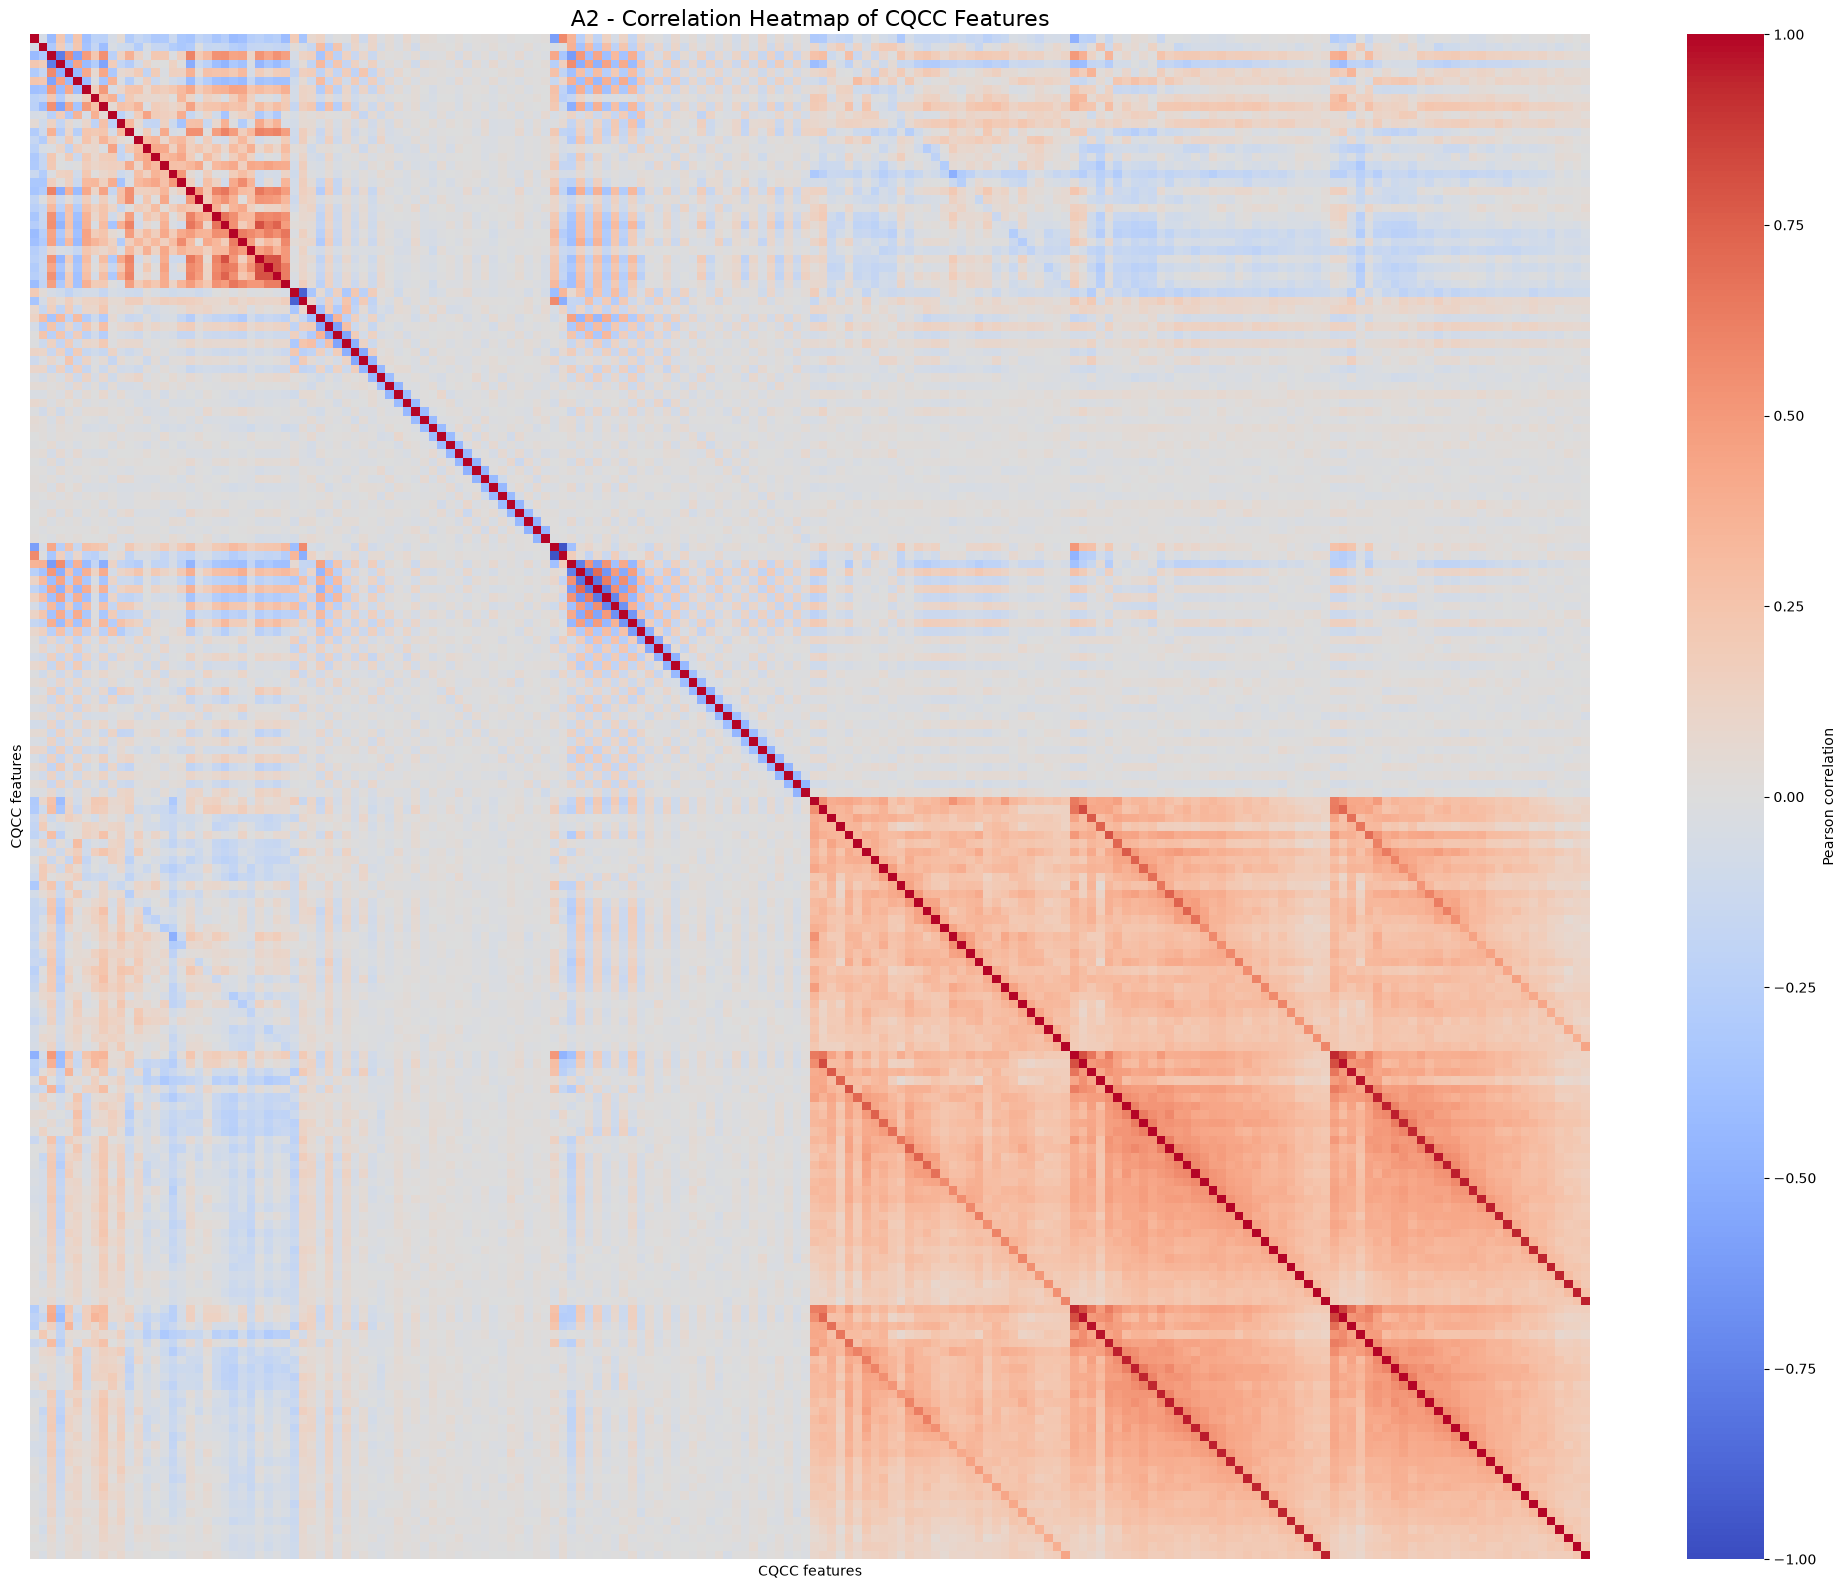

Top 20 strongly correlated feature pairs:


,Feature 1,Feature 2,Correlation,Absolute Correlation
21931,CQCC_032_Std,CQCC_062_Std,0.972639,0.972639
22112,CQCC_033_Std,CQCC_063_Std,0.971168,0.971168
22293,CQCC_034_Std,CQCC_064_Std,0.970527,0.970527
23922,CQCC_043_Std,CQCC_073_Std,0.964444,0.964444
10861,CQCC_061_Mean,CQCC_062_Mean,-0.963071,0.963071
22474,CQCC_035_Std,CQCC_065_Std,0.959956,0.959956
24103,CQCC_044_Std,CQCC_074_Std,0.957343,0.957343
23741,CQCC_042_Std,CQCC_072_Std,0.954674,0.954674
26637,CQCC_058_Std,CQCC_088_Std,0.953549,0.953549
24465,CQCC_046_Std,CQCC_076_Std,0.953335,0.953335


Top 20 features by absolute correlation with the class label:


,Correlation with Label
CQCC_003_Mean,-0.773049
CQCC_004_Mean,0.711512
CQCC_025_Mean,-0.599452
CQCC_022_Mean,-0.564965
CQCC_006_Mean,0.551113
CQCC_019_Mean,-0.502926
CQCC_024_Mean,-0.490028
CQCC_031_Std,-0.477594
CQCC_063_Mean,0.476010
CQCC_064_Mean,-0.462724


Correlation heatmap and tables saved in: C:\Users\tanki\Downloads\Lab10_ASVspoof_Notebook\Lab10_outputs


In [5]:
correlation_matrix = X.corr(method='pearson')

plt.figure(figsize=(20, 16))
sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={'label': 'Pearson correlation'},
)
plt.title('A2 - Correlation Heatmap of CQCC Features', fontsize=16)
plt.xlabel('CQCC features')
plt.ylabel('CQCC features')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'A2_cqcc_correlation_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

# Extract the strongest unique feature-feature pairs (upper triangle only).
upper_triangle_mask = np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1)
correlation_pairs = (
    correlation_matrix.where(upper_triangle_mask)
    .stack()
    .rename('Correlation')
    .reset_index()
)
correlation_pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']
correlation_pairs['Absolute Correlation'] = correlation_pairs['Correlation'].abs()
strongest_pairs = correlation_pairs.sort_values(
    'Absolute Correlation', ascending=False,
).head(20)

# Show the relationship of each feature with the binary class label.
feature_label_correlation = X.assign(Label=y).corr(numeric_only=True)['Label'].drop('Label')
feature_label_correlation = feature_label_correlation.reindex(
    feature_label_correlation.abs().sort_values(ascending=False).index
)

print('Top 20 strongly correlated feature pairs:')
display(strongest_pairs)
print('Top 20 features by absolute correlation with the class label:')
display(feature_label_correlation.head(20).rename('Correlation with Label').to_frame())

strongest_pairs.to_csv(OUTPUT_DIR / 'A2_top_feature_correlations.csv', index=False)
feature_label_correlation.rename('Correlation with Label').to_csv(
    OUTPUT_DIR / 'A2_feature_label_correlations.csv',
)
print('Correlation heatmap and tables saved in:', OUTPUT_DIR.resolve())

# A3. PCA with 99% Explained Variance

Original number of features: 180
Number of PCA components selected: 136
Explained variance retained: 0.990550 (99.06%)


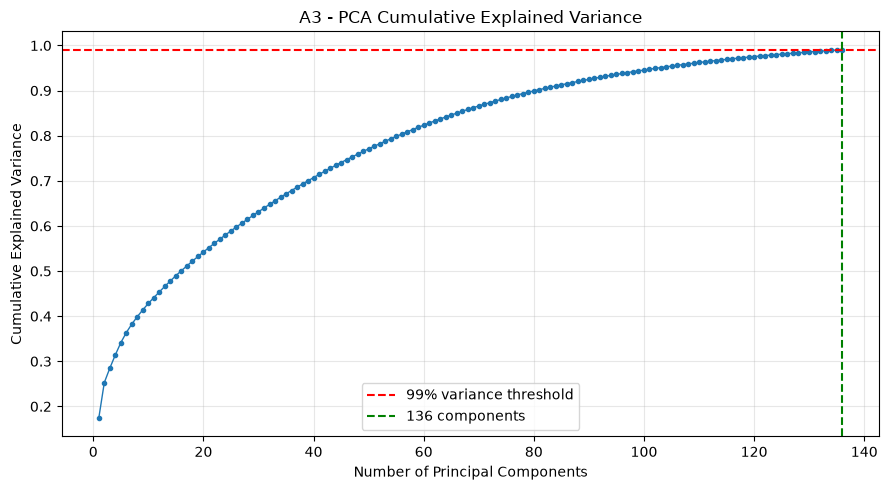

In [6]:
# First fit PCA by itself to report the number of components needed for 99% variance.
pca_preprocessor = make_preprocessing_pipeline(include_pca=True)
X_train_pca = pca_preprocessor.fit_transform(X_train)
X_test_pca = pca_preprocessor.transform(X_test)
pca_model = pca_preprocessor.named_steps['pca']

n_components = int(pca_model.n_components_)
retained_variance = float(np.sum(pca_model.explained_variance_ratio_))

print('Original number of features:', X_train.shape[1])
print('Number of PCA components selected:', n_components)
print(f'Explained variance retained: {retained_variance:.6f} ({retained_variance * 100:.2f}%)')

cumulative_variance = np.cumsum(pca_model.explained_variance_ratio_)
plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance, marker='.', linewidth=1)
plt.axhline(y=0.99, color='red', linestyle='--', label='99% variance threshold')
plt.axvline(x=n_components, color='green', linestyle='--', label=f'{n_components} components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('A3 - PCA Cumulative Explained Variance')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'A3_pca_cumulative_variance.png', dpi=180, bbox_inches='tight')
plt.show()

In [7]:
classifiers_for_pca, unavailable_pca_models = build_classifier_instances()
pca_comparison_rows = []

for classifier_name in classifiers_for_pca:
    print(f'Evaluating {classifier_name}: original features and PCA features...')

    # Use a fresh classifier for the original-feature experiment.
    original_classifier = build_classifier_instances()[0][classifier_name]
    original_metrics, _ = run_original_or_pca_experiment(
        original_classifier, use_pca=False,
    )
    original_metrics['Classifier'] = classifier_name
    original_metrics['Feature Set'] = 'Original'
    pca_comparison_rows.append(original_metrics)

    # Use a fresh classifier for the PCA experiment.
    reduced_classifier = build_classifier_instances()[0][classifier_name]
    reduced_metrics, _ = run_original_or_pca_experiment(
        reduced_classifier, use_pca=True,
    )
    reduced_metrics['Classifier'] = classifier_name
    reduced_metrics['Feature Set'] = 'PCA (99% variance)'
    pca_comparison_rows.append(reduced_metrics)

pca_comparison_df = pd.DataFrame(pca_comparison_rows)
pca_comparison_df = pca_comparison_df[
    [
        'Classifier', 'Feature Set', 'Number of Features', 'Explained Variance',
        'Accuracy', 'Balanced Accuracy', 'Precision (spoof)', 'Recall (spoof)',
        'F1 (spoof)', 'ROC-AUC', 'PR-AUC', 'MCC', 'Fit Time (seconds)',
    ]
]

print('A3 - Original features vs PCA-transformed features:')
display(pca_comparison_df.sort_values(['Classifier', 'Feature Set']))
pca_comparison_df.to_csv(OUTPUT_DIR / 'A3_original_vs_pca_results.csv', index=False)

print('Optional classifiers not available:', unavailable_pca_models)

Evaluating Support Vector Machine: original features and PCA features...


C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\tanki\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Evaluating Decision Tree: original features and PCA features...
Evaluating Random Forest: original features and PCA features...
Evaluating AdaBoost: original features and PCA features...
Evaluating Naive Bayes: original features and PCA features...
Evaluating CatBoost: original features and PCA features...
Evaluating XGBoost: original features and PCA features...
A3 - Original features vs PCA-transformed features:


,Classifier,Feature Set,Number of Features,Explained Variance,Accuracy,Balanced Accuracy,Precision (spoof),Recall (spoof),F1 (spoof),ROC-AUC,PR-AUC,MCC,Fit Time (seconds)
6,AdaBoost,Original,180,NaN,0.985075,0.985083,0.980263,0.990033,0.985124,0.999263,0.999276,0.970198,3.370912
7,AdaBoost,PCA (99% variance),136,0.99055,0.970149,0.970127,0.982935,0.956811,0.969697,0.995072,0.985068,0.940627,2.761792
10,CatBoost,Original,180,NaN,0.996683,0.996683,0.996678,0.996678,0.996678,0.999945,0.999945,0.993366,15.135304
11,CatBoost,PCA (99% variance),136,0.99055,0.986733,0.986733,0.986711,0.986711,0.986711,0.999054,0.998999,0.973466,11.507352
2,Decision Tree,Original,180,NaN,0.968491,0.968488,0.970000,0.966777,0.968386,0.968488,0.954358,0.936986,0.235515
3,Decision Tree,PCA (99% variance),136,0.99055,0.941957,0.941943,0.949324,0.933555,0.941374,0.941943,0.919414,0.884032,0.271726
8,Naive Bayes,Original,180,NaN,0.917081,0.917081,0.916944,0.916944,0.916944,0.971937,0.960951,0.834162,0.005938
9,Naive Bayes,PCA (99% variance),136,0.99055,0.799337,0.799372,0.786624,0.820598,0.803252,0.890123,0.884801,0.599258,0.006584
4,Random Forest,Original,180,NaN,0.996683,0.996683,0.996678,0.996678,0.996678,0.999989,0.999989,0.993366,1.276471
5,Random Forest,PCA (99% variance),136,0.99055,0.973466,0.973477,0.967213,0.980066,0.973597,0.995858,0.995290,0.947016,1.282908


Optional classifiers not available: []


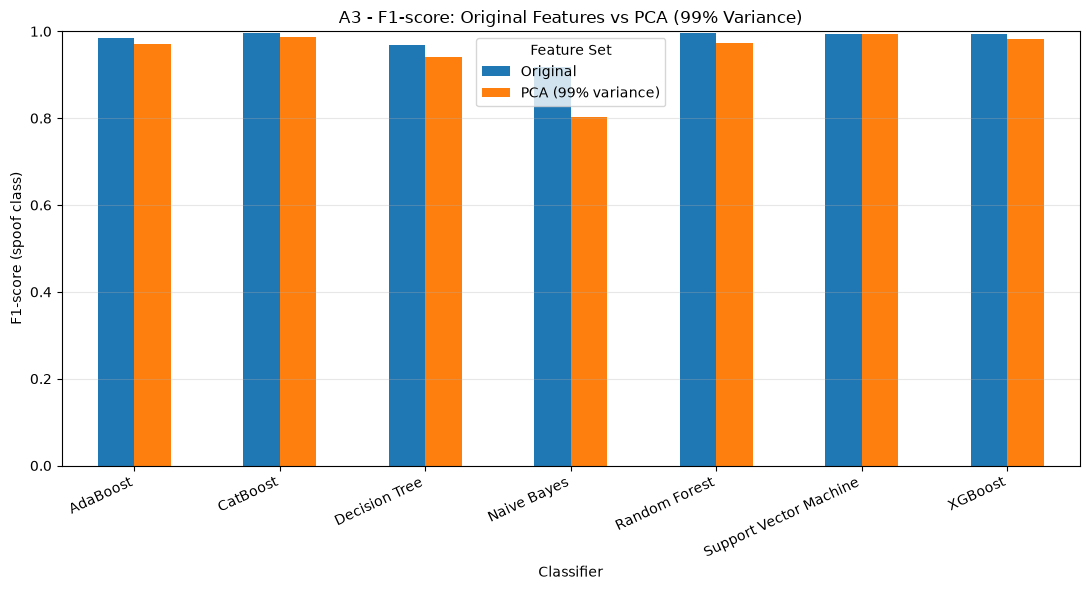

F1-score change after PCA:


Feature Set,Original,PCA (99% variance),F1 Change (PCA - Original)
Classifier,,,
Support Vector Machine,0.993377,0.993377,0.000000
CatBoost,0.996678,0.986711,-0.009967
XGBoost,0.995008,0.981818,-0.013190
AdaBoost,0.985124,0.969697,-0.015427
Random Forest,0.996678,0.973597,-0.023080
Decision Tree,0.968386,0.941374,-0.027012
Naive Bayes,0.916944,0.803252,-0.113691


In [8]:
# Plot F1-score comparison for original and reduced feature sets.
f1_plot_data = pca_comparison_df.pivot(
    index='Classifier', columns='Feature Set', values='F1 (spoof)',
)
ax = f1_plot_data.plot(kind='bar', figsize=(11, 6))
ax.set_title('A3 - F1-score: Original Features vs PCA (99% Variance)')
ax.set_xlabel('Classifier')
ax.set_ylabel('F1-score (spoof class)')
ax.set_ylim(0, 1)
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'A3_original_vs_pca_f1_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

# Compact table showing the change in F1 after dimensionality reduction.
f1_comparison = f1_plot_data.copy()
f1_comparison['F1 Change (PCA - Original)'] = (
    f1_comparison['PCA (99% variance)'] - f1_comparison['Original']
)
print('F1-score change after PCA:')
display(f1_comparison.sort_values('F1 Change (PCA - Original)', ascending=False))
f1_comparison.to_csv(OUTPUT_DIR / 'A3_f1_change_after_pca.csv')

In [9]:
print('Lab 10 notebook experiments completed.')
print('\nGenerated output files:')
for output_path in sorted(OUTPUT_DIR.iterdir()):
    print('-', output_path.name)


Lab 10 notebook experiments completed.

Generated output files:
- A1_stacking_results.csv
- A2_cqcc_correlation_heatmap.png
- A2_feature_label_correlations.csv
- A2_top_feature_correlations.csv
- A3_f1_change_after_pca.csv
- A3_original_vs_pca_f1_comparison.png
- A3_original_vs_pca_results.csv
- A3_pca_cumulative_variance.png
